In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer

In [3]:
newsgroups = fetch_20newsgroups(
    subset='train',
    remove=('headers', 'footers', 'quotes')
)

documents = newsgroups.data

print("Number of Documents:", len(documents))

Number of Documents: 11314


In [4]:
vectorizer = CountVectorizer(
    stop_words='english',
    max_features=5000,
    min_df=5
)

X = vectorizer.fit_transform(documents)

vocabulary = vectorizer.get_feature_names_out()

print("Document-Term Matrix Shape:", X.shape)
print("Vocabulary Size:", len(vocabulary))

Document-Term Matrix Shape: (11314, 5000)
Vocabulary Size: 5000


In [5]:
word_counts = np.array(X.sum(axis=0)).flatten()

print("Total Words:", word_counts.sum())
print("First 10 Counts:")
print(word_counts[:10])

Total Words: 884959
First 10 Counts:
[1204  693  228  262  211  348   42  170  162   76]


In [6]:
def mle_estimate(counts):
    theta = counts / counts.sum()
    return theta

In [7]:
theta_mle = mle_estimate(word_counts)

print("First 10 MLE Probabilities:")
print(theta_mle[:10])

First 10 MLE Probabilities:
[1.36051501e-03 7.83087126e-04 2.57639054e-04 2.96058913e-04
 2.38429125e-04 3.93238557e-04 4.74598258e-05 1.92099295e-04
 1.83059328e-04 8.58796848e-05]


In [8]:
def map_estimate(counts, alpha):

    theta = counts + alpha - 1

    theta = theta / theta.sum()

    return theta

In [9]:
priors = [0.5, 1, 2, 10]

map_results = {}

for alpha in priors:
    map_results[alpha] = map_estimate(word_counts, alpha)

print("MAP estimation completed.")

MAP estimation completed.


In [10]:
def show_top_words(theta, vocabulary, n=10):

    indices = np.argsort(theta)[::-1][:n]

    for i in indices:
        print(vocabulary[i], ":", round(theta[i],6))

In [11]:
print("Top 10 Words using MLE")

show_top_words(theta_mle, vocabulary)

Top 10 Words using MLE
ax : 0.070497
max : 0.005181
people : 0.004636
like : 0.004479
don : 0.00439
just : 0.00424
know : 0.00394
use : 0.003592
think : 0.003402
time : 0.003354


In [12]:
for alpha in priors:

    print("\nMAP with Alpha =", alpha)

    show_top_words(map_results[alpha], vocabulary)


MAP with Alpha = 0.5
ax : 0.070696
max : 0.005195
people : 0.004649
like : 0.004491
don : 0.004402
just : 0.004251
know : 0.003951
use : 0.003602
think : 0.003411
time : 0.003363

MAP with Alpha = 1
ax : 0.070497
max : 0.005181
people : 0.004636
like : 0.004479
don : 0.00439
just : 0.00424
know : 0.00394
use : 0.003592
think : 0.003402
time : 0.003354

MAP with Alpha = 2
ax : 0.070102
max : 0.005153
people : 0.004611
like : 0.004455
don : 0.004366
just : 0.004217
know : 0.003919
use : 0.003573
think : 0.003384
time : 0.003336

MAP with Alpha = 10
ax : 0.067095
max : 0.00494
people : 0.004422
like : 0.004272
don : 0.004187
just : 0.004044
know : 0.003759
use : 0.003428
think : 0.003247
time : 0.003201


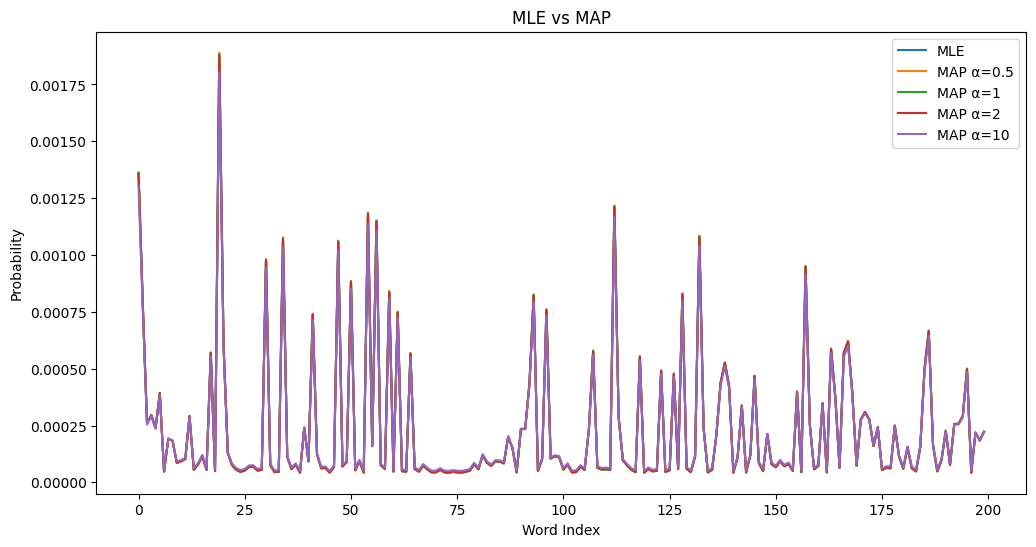

In [13]:
plt.figure(figsize=(12,6))

plt.plot(theta_mle[:200], label="MLE")

for alpha in priors:
    plt.plot(map_results[alpha][:200], label=f"MAP α={alpha}")

plt.title("MLE vs MAP")
plt.xlabel("Word Index")
plt.ylabel("Probability")

plt.legend()

plt.show()

In [14]:
print("Mean Absolute Difference from MLE\n")

for alpha in priors:

    difference = np.mean(np.abs(theta_mle - map_results[alpha]))

    print("Alpha =", alpha, " Difference =", difference)

Mean Absolute Difference from MLE

Alpha = 0.5  Difference = 4.812940696454126e-07
Alpha = 1  Difference = 0.0
Alpha = 2  Difference = 9.544760677856381e-07
Alpha = 10  Difference = 8.220793713802391e-06


In [15]:
print("Observations")
print("- MLE uses only observed word frequencies.")
print("- MAP incorporates prior information using Dirichlet priors.")
print("- Alpha = 1 gives the same result as MLE.")
print("- Larger alpha values smooth the probabilities.")
print("- Smaller alpha values produce a more peaked distribution.")

Observations
- MLE uses only observed word frequencies.
- MAP incorporates prior information using Dirichlet priors.
- Alpha = 1 gives the same result as MLE.
- Larger alpha values smooth the probabilities.
- Smaller alpha values produce a more peaked distribution.
